In [27]:
# Packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Linear Regression
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
# Train Test
from sklearn.model_selection import train_test_split, KFold, cross_val_score
# Preprocessing
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
# Pipeline
from sklearn.pipeline import Pipeline # To maintain flow of data while fitting data into model.
# Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv('Dataset/Real estate.csv')
df.head(2)

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2


In [3]:
df = df.drop(columns = ['No', 'X1 transaction date'])

In [4]:
df.columns

Index(['X2 house age', 'X3 distance to the nearest MRT station',
       'X4 number of convenience stores', 'X5 latitude', 'X6 longitude',
       'Y house price of unit area'],
      dtype='str')

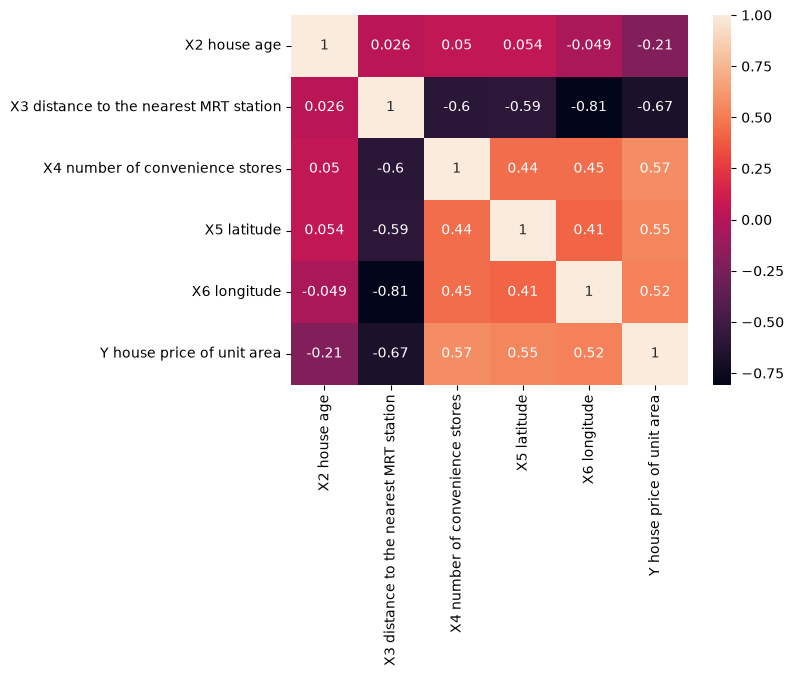

In [5]:
df_corr = df.corr()

sns.heatmap(df_corr, annot=True)
plt.show()

<Axes: ylabel='X3 distance to the nearest MRT station'>

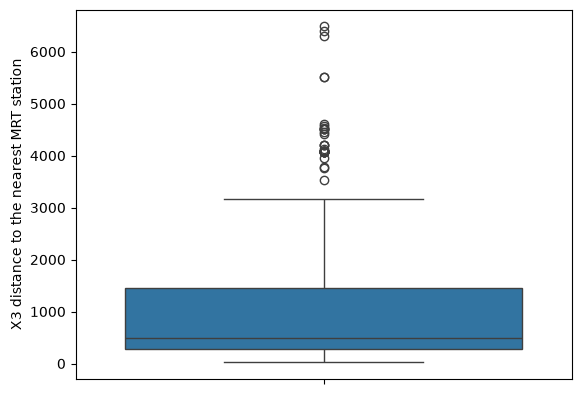

In [6]:
sns.boxplot(df['X3 distance to the nearest MRT station'])

## Feature and Target

In [7]:
features = ['X2 house age', 'X3 distance to the nearest MRT station', 'X4 number of convenience stores', 
            'X5 latitude', 'X6 longitude']
target = 'Y house price of unit area'

In [8]:
X = df[features]
Y = df[target]

## Train Test Split

In [9]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

## Feature Scaling

In [10]:
'''
- fit_transform(feature 80% training data)
    - fit -> learning -> calculation of mean and sd
    - transform -> implement -> implementation of mean and sd into formula (Xi - mean) / sd
    
- transform(feature 20% testing data)
    - transform -> implement -> (Xi - mean) / sd
'''

'\n- fit_transform(feature 80% training data)\n    - fit -> learning -> calculation of mean and sd\n    - transform -> implement -> implementation of mean and sd into formula (Xi - mean) / sd\n\n- transform(feature 20% testing data)\n    - transform -> implement -> (Xi - mean) / sd\n'

In [11]:
scaler = StandardScaler()
X_train_scale = scaler.fit_transform(X_train)
X_test_scale = scaler.transform(X_test)

## Model Implementation

In [12]:
model = LinearRegression()

In [13]:
model.fit(X_train_scale, Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[-3.06,-5.54, 3.26, 2.94,-0.36]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,38.39
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](5,)","[29.57,18.38,14.39,13.51, 7.32]"


In [14]:
Y_pred = model.predict(X_test_scale)
Y_pred

array([47.74180481, 41.95484652, 44.5399885 , 41.33697932, 30.28548   ,
       42.84474934, 45.98717123, 45.90599326, 24.78369465, 52.02068924,
       32.23880597, 34.77542016, 39.51392044, 24.90203898, 35.73984968,
       32.99552705, 41.96863217, 46.98662328, 31.50100311, 44.49258341,
        2.21362693, 33.64381059, 47.764103  , 43.56374399, 14.07301949,
       41.29883092, 14.73315281, 44.5399885 , 36.13972668, 37.76019401,
       11.66211419, 39.22848089, 37.83881729, 28.61334713, 45.93500741,
       31.52925298, 52.2101045 , 15.18188713, 46.84531477, 40.47464938,
       36.01694465, 40.58052131, 48.38869976, 39.8943259 , 42.00896517,
       48.22742934, 45.07252677, 23.5290158 , 49.9849698 , 48.13933326,
       47.74180481, 48.54209921, 40.94754085, 42.54642454, 36.38766353,
       15.15482781, 35.13348041, 36.39866246, 30.20430203, 45.90599326,
       33.69672647, 32.65567761, 15.15482781, 11.8739673 ,  8.74877596,
       33.67086991, 29.81801432, 45.24751413, 34.2425491 , 30.54

## Adjusting R2 Score

In [20]:
def adjust_r2(r2, n, p):
    return 1 - ((1 - r2) * (n - 1)) / (n - p - 1)

n_sample = X_test.shape[0] # Total rows of test data
p = X_train.shape[1] # Total Collumns of train data

## Metrics

In [21]:
mae = mean_absolute_error(Y_test, Y_pred)
mse = mean_squared_error(Y_test, Y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(Y_test, Y_pred)
adjustR2 = adjust_r2(r2, n_sample, p)

In [22]:
print(f'Mean Absolute Error (MAE): {mae}')
print(f'Mean Squared Error (MSE): {mse}')
print(f'Root Mean Squared Error (RMSE): {rmse}')
print(f'R2 Score (Residual Score): {r2}')
print(f'Adjusted R2 Score: {adjustR2}')

Mean Absolute Error (MAE): 5.350138374356212
Mean Squared Error (MSE): 54.580945200862146
Root Mean Squared Error (RMSE): 7.3878917967754605
R2 Score (Residual Score): 0.6746481382828176
Adjusted R2 Score: 0.653521394015468


## Visualization

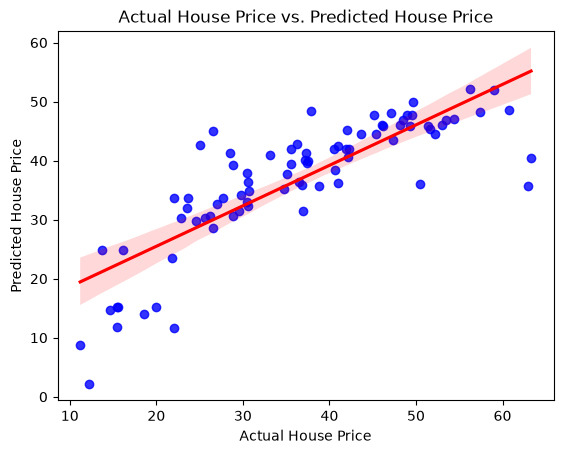

In [17]:
sns.regplot(x=Y_test, y=Y_pred, color='blue', line_kws={'color': 'red'})
plt.xlabel('Actual House Price')
plt.ylabel('Predicted House Price')
plt.title('Actual House Price vs. Predicted House Price')
plt.show()

## Linear Regression Regularization Models

In [ ]:
'''
1. Adjusting R2 Score
    -> 1 - ((1 - r2) * (n - 1)) / (n - p - 1)
    -> R2 -> Residual Score
    -> n -> Test Data Shape
    -> p -> Train Data Shape

2. Cross Validation
    -> If our dataset is small to medium sized.
    -> To make model learn more patterns about data.

3. Polynomial Regression
    -> If our data has outliers and dependent features then use polynomal regression.

4. Ridge Regression (L1)
    -> Convert high weight data to near 0 weight. 

5. Lasso Regression (L2)
    -> Removes high weight data.

6. Elastic Net
    -> Combination of both Ridge Regression and Lasso Regression.
'''

### Cross Validation

In [36]:
kfold = KFold(n_splits=5, shuffle=True, random_state=42) # cross validation
cv_score = cross_val_score(model, scaler.transform(X), Y, scoring='r2') # cross validation score

In [37]:
print(f'Cross Validation Scores: {cv_score}')
print(f'Average CV Score: {cv_score.mean()}')

Cross Validation Scores: [0.68463546 0.53209757 0.66649314 0.42112676 0.57912236]
Average CV Score: 0.5766950593066446


### Polynomial Regression

In [38]:
'''
= degree = 2 -> check 2 features at ones to know the features are dependent or independent
    x1, x2, x3
    - x1.x2, x1^2, x2^2
    - x1.x3, x1^2, x3^2
    - x2.x3, x2^2, x3^3
hypothesis testing -> chi-squared test -> Statistics
'''
poly_reg = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('linear', LinearRegression())
])

poly_reg.fit(X_train_scale, Y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('poly', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](5,)","[ 0.,-0., 0., 0., 0.]"


In [39]:
poly_pred = poly_reg.predict(X_test_scale)

In [40]:
poly_mae = mean_absolute_error(Y_test, poly_pred)
poly_mse = mean_squared_error(Y_test, poly_pred)
poly_rmse = np.sqrt(poly_mse)
poly_r2 = r2_score(Y_test, poly_pred)
poly_adjustR2 = adjust_r2(poly_r2, n_sample, p)

In [41]:
print(f'Polynomial Regression Mean Absolute Error (MAE): {poly_mae}')
print(f'Polynomial Regression Mean Squared Error (MSE): {poly_mse}')
print(f'Polynomial Regression Root Mean Squared Error (RMSE): {poly_rmse}')
print(f'Polynomial Regression R2 Score (Residual Score): {poly_r2}')
print(f'Polynomial Regression Adjusted R2 Score: {poly_adjustR2}')

Polynomial Regression Mean Absolute Error (MAE): 4.81217682058443
Polynomial Regression Mean Squared Error (MSE): 41.85048243854701
Polynomial Regression Root Mean Squared Error (RMSE): 6.469194883333397
Polynomial Regression R2 Score (Residual Score): 0.7505332250103934
Polynomial Regression Adjusted R2 Score: 0.7343340837773021


### Ridge Regression

In [50]:
ridge_reg = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('ridge', Ridge(alpha=1.0))
])
ridge_reg.fit(X_train_scale, Y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('poly', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](5,)","[ 0.,-0., 0., 0., 0.]"


In [51]:
ridge_pred = ridge_reg.predict(X_test_scale)

In [53]:
ridge_mae = mean_absolute_error(Y_test, ridge_pred)
ridge_mse = mean_squared_error(Y_test, ridge_pred)
ridge_rmse = np.sqrt(ridge_mse)
ridge_r2 = r2_score(Y_test, ridge_pred)
ridge_adjustR2 = adjust_r2(ridge_r2, n_sample, p)

In [54]:
print(f'Ridge Regression Mean Absolute Error (MAE): {ridge_mae}')
print(f'Ridge Regression Mean Squared Error (MSE): {ridge_mse}')
print(f'Ridge Regression Root Mean Squared Error (RMSE): {ridge_rmse}')
print(f'Ridge Regression R2 Score (Residual Score): {ridge_r2}')
print(f'Ridge Regression Adjusted R2 Score: {ridge_adjustR2}')

Ridge Regression Mean Absolute Error (MAE): 4.773512156892724
Ridge Regression Mean Squared Error (MSE): 41.77960040677209
Ridge Regression Root Mean Squared Error (RMSE): 6.463714134054204
Ridge Regression R2 Score (Residual Score): 0.7509557461103011
Ridge Regression Adjusted R2 Score: 0.7347840413122688


### Lasso Regression

In [76]:
lasso_reg = Pipeline([
    ('scaler', StandardScaler()),
    # ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('lasso', Lasso(alpha=0.1))
])
lasso_reg.fit(X_train_scale, Y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('lasso', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](5,)","[ 0.,-0., 0., 0., 0.]"


In [77]:
lasso_pred = lasso_reg.predict(X_test_scale)

In [78]:
lasso_mae = mean_absolute_error(Y_test, lasso_pred)
lasso_mse = mean_squared_error(Y_test, lasso_pred)
lasso_rmse = np.sqrt(lasso_mse)
lasso_r2 = r2_score(Y_pred, lasso_pred)
lasso_adjustR2 = adjust_r2(lasso_r2, n_sample, p)

In [79]:
print(f'Lasso Regression Mean Absolute Error (MAE): {lasso_mae}')
print(f'Lasso Regression Mean Squared Error (MSE): {lasso_mse}')
print(f'Lasso Regression Root Mean Squared Error (RMSE): {lasso_rmse}')
print(f'Lasso Regression R2 Score (Residual Score): {lasso_r2}')
print(f'Lasso Regression Adjusted R2 Score: {lasso_adjustR2}')

Lasso Regression Mean Absolute Error (MAE): 5.363866509345238
Lasso Regression Mean Squared Error (MSE): 54.33196323420446
Lasso Regression Root Mean Squared Error (RMSE): 7.371021858209651
Lasso Regression R2 Score (Residual Score): 0.9993953630088642
Lasso Regression Adjusted R2 Score: 0.9993561008665827


### Elastic Net

In [99]:
elastic_reg = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('elastic', ElasticNet(alpha=0.1, l1_ratio=0.5))
])
elastic_reg.fit(X_train_scale, Y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('poly', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](5,)","[ 0.,-0., 0., 0., 0.]"


In [100]:
elastic_pred = elastic_reg.predict(X_test_scale)

In [101]:
elastic_mae = mean_absolute_error(Y_test, elastic_pred)
elastic_mse = mean_squared_error(Y_test, elastic_pred)
elastic_rmse = np.sqrt(elastic_mse)
elastic_r2 = r2_score(Y_pred, elastic_pred)
elastic_adjustR2 = adjust_r2(elastic_r2, n_sample, p)

In [102]:
print(f'Elastic Net Regression Mean Absolute Error (MAE): {elastic_mae}')
print(f'Elastic Net Regression Mean Squared Error (MSE): {elastic_mse}')
print(f'Elastic Net Regression Root Mean Squared Error (RMSE): {elastic_rmse}')
print(f'Elastic Net Regression R2 Score (Residual Score): {elastic_r2}')
print(f'Elastic Net Regression Adjusted R2 Score: {elastic_adjustR2}')

Elastic Net Regression Mean Absolute Error (MAE): 4.6246282051766725
Elastic Net Regression Mean Squared Error (MSE): 40.22813706404068
Elastic Net Regression Root Mean Squared Error (RMSE): 6.3425654954474595
Elastic Net Regression R2 Score (Residual Score): 0.7993086392816111
Elastic Net Regression Adjusted R2 Score: 0.7862767327414559


In [103]:
elastic_kfold = KFold(n_splits=5, shuffle=True, random_state=42) # cross validation
elastic_cv_score = cross_val_score(elastic_reg, scaler.transform(X), Y, scoring='r2') # cross validation score

print(elastic_cv_score)
print(elastic_cv_score.mean())

[0.76595403 0.65458248 0.75879049 0.46774572 0.69753974]
0.6689224940893895
